<p>
    <b>ADA Facility report</b><br>
    <b>Gulbenkian Institute for Molecular Medicine</b><br>
    <b>Oeiras, PT</b>
</p>
<br>

# Setup

## Database Import

To make these sequences more "stable", we are working locally with reference files from the latest version of reference genome from *Mus musculus* provided by ENSEMBL (version 116).

* `.gtf` file - https://ftp.ensembl.org/pub/release-116/gtf/mus_musculus/Mus_musculus.GRCm39.116.gtf.gz
* `.fasta` file - https://ftp.ensembl.org/pub/release-116/fasta/mus_musculus/dna/Mus_musculus.GRCm39.dna.primary_assembly.fa.gz

To work with the reference files from ENSEMBL, we are using the `pyranges` package (https://pyranges.readthedocs.io/en/latest/index.html)

In [2]:
#| label: setup_packages_paths
#| code-fold: true
#| code-summary: "Setup: Imports and Reference File Paths"
#| output: false
import pyranges as pr
import pyfaidx
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
import os
import session_info

# -------- Setting the Path for the necessary files -------- #

GTF_v116 = "/srv/ext_home/asbarros/genomes/mmusculus/Ensembl_v116/Mus_musculus.GRCm39.116.gtf.gz"
FA_v116  = "/srv/ext_home/asbarros/genomes/mmusculus/Ensembl_v116/Mus_musculus.GRCm39.dna.primary_assembly.fa"

# -------- Reference Genome (.fasta) -------- #
#fa  = pyfaidx.Fasta(FA_v116)                                                 # Index the fasta file (creating the .fai file) - Only requires to be done one time

In [3]:
#| label: gtf_import
#| code-fold: true
#| code-summary: "Import and Filter Reference GTF"
#| output: false
# -------- Reference GTF -------- #
gtf = pr.read_gtf(GTF_v116, duplicate_attr=True)                              # Import the GTF file, which has all the information necessary to extract the coordinates. Keep all attributes in single string (e.g. keep tag 'Ensembl_canonical')
gtf_canonical = gtf[(gtf.Feature == "transcript") & 
                     gtf.tag.str.contains("Ensembl_canonical", na=False)]     # Filter to include only transcripts that contain the tag "Ensembl_canonical" (which corresponds to canonical transcripts)

## Promotor Gene Retrieval

A list of genes was given by the user to check for transcription factors motifs in the promotor:

Transcription Factor genes: *Nfe2l2, SpiC, Bach1*
Regulation Network of SpiC: *Blvra, Hmox1, Vcam1, Slc40a1, Nqo1, Gsr, Slc7a11, Gclc, Cat, Gpx4, Gclm, Gss, Txnrd1, Fth1, Nfs1, Cisd1, Aifm2, Acsl4, Acsl2, LPCAT3, G6PDX, PGD, ME1, IDH1, Nox1, Elovl7, Ido1, ALAS1, DHODH, ACSL3, SCD1, *SCD5*.
Control gene of Bach1: *Nqo1*

A few genes were found under other name in the genome used in this work:
- Acsl2 was found by the Acsl1 synonym name (https://www.uniprot.org/uniprotkb/P41216/entry);
- Aifm2 is the gene name of Fsp1 which wasn't found, and therefore not considered (https://www.uniprot.org/uniprotkb/Q8BUE4/entry);
- There was no correspondence found for SCD5 in mice in this genome, nor in uniprot.

The promoter region for each gene was defined as **−2,000 bp to +200 bp relative to the transcription start site (TSS)** of the canonical transcript. This interval was selected because it encompasses the proximal regulatory regions where transcription factor binding is most frequently observed.

More specifically:

- The **−2,000 bp upstream region** captures the proximal promoter and many of the cis-regulatory transcription factor binding sites.
- The **+200 bp downstream region** includes the TSS-proximal sequence, which often contains core promoter elements and regulatory motifs that overlap the transcription start site.
- The **TSS of the canonical transcript** was used as the reference coordinate to ensure a consistent and standardized definition of promoter regions across all analyzed genes.

These promoter sequences were subsequently used for transcription factor binding site analysis to evaluate the potential for direct SpiC-mediated transcriptional regulation, or indirect regulation through Nfe2l2-mediated transcriptional regulation.

### Extract transcript coordinates

In [4]:
#| label: gene_subset
#| code-fold: true
#| code-summary: "Select Canonical Transcripts for Genes of Interest"
#| output: false
# List of genes of interest

#the gene name needs to be have a format with the first letter only in Caps to be found
genes = ["Spic", "Nfe2l2", "Bach1", "Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1", "Scd5", "Nqo1", "Hmox1"]             

gtf_sub = gtf_canonical[gtf_canonical.gene_name.isin(genes)]      # Using the subset for canonical transcripts, select the ones for the genes of interest.

found   = set(gtf_sub.df['gene_name'])       # drop .df on PyRanges 1.x
missing = set(genes) - found

print(f"{len(found)}/{len(set(genes))} genes found")
if missing:
    print("Missing:", sorted(missing))

print(f"Are there duplicated values: {gtf_sub.df['gene_name'].duplicated().any()}")                 # Check if more than one transcript was given per gene_name; if this is true - check the object

34/35 genes found
Missing: ['Scd5']
Are there duplicated values: False


Register the Start & End coordinates

In [5]:
#| label: gtf_sub_preview
#| code-fold: true
#| code-summary: "Selected Transcript Coordinates"
#| output: asis
print(gtf.columns.tolist())
gtf_sub[['Chromosome', 'gene_id', 'gene_name', 'transcript_id', 'Source', 'Feature', 'Start', 'End', 'Strand', 'ID']]      # Inspect the selected canonical transcripts (one per gene of interest)

['Chromosome', 'Source', 'Feature', 'Start', 'End', 'Score', 'Strand', 'Frame', 'gene_id', 'gene_version', 'gene_name', 'gene_source', 'gene_biotype', 'transcript_id', 'transcript_version', 'transcript_name', 'transcript_source', 'transcript_biotype', 'tag', 'transcript_support_level', 'exon_number', 'exon_id', 'exon_version', 'ccds_id', 'protein_id', 'protein_version']


/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])
/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])


,Chromosome,gene_id,gene_name,Start,End,Strand,transcript_id,Source,Feature
0,1,ENSMUSG00000032883,Acsl3,78635536,78685460,+,ENSMUST00000142704,ensembl_havana,transcript
1,1,ENSMUSG00000025993,Slc40a1,45947210,45964818,-,ENSMUST00000027137,ensembl_havana,transcript
2,1,ENSMUSG00000025950,Idh1,65196780,65218340,-,ENSMUST00000097709,ensembl_havana,transcript
3,2,ENSMUSG00000001999,Blvra,126912566,126939017,+,ENSMUST00000002064,ensembl_havana,transcript
4,2,ENSMUSG00000027187,Cat,103284193,103315505,-,ENSMUST00000028610,ensembl_havana,transcript
5,2,ENSMUSG00000027610,Gss,155405095,155434730,-,ENSMUST00000079691,ensembl_havana,transcript
6,2,ENSMUSG00000027618,Nfs1,155965555,155986374,-,ENSMUST00000029147,ensembl_havana,transcript
7,2,ENSMUSG00000015839,Nfe2l2,75504738,75534985,-,ENSMUST00000102672,ensembl_havana,transcript
8,3,ENSMUSG00000028124,Gclm,122039125,122065061,+,ENSMUST00000029769,ensembl_havana,transcript
9,3,ENSMUSG00000027737,Slc7a11,50319386,50398063,-,ENSMUST00000029297,ensembl_havana,transcript


Plus strand (+): transcription goes left→right along the reference. The biological start (TSS, 5′ end) is at Start, and the 3′ end is at End.
Minus strand (-): transcription goes right→left along the reference. The biological start (TSS, 5′ end) is at End, and the 3′ end is at Start.

### Extract promoter coordinates

In [6]:
#| label: promoter_coords
#| code-fold: true
#| code-summary: "Compute 2 kb Promoter Coordinates"
#| output: false
prom_2kb = gtf_sub.five_end().slack({"5": 2000, "3": 200})                             # 2kb promoters. Strand-Aware function, that will change the columns 'Start' & 'End' in the PyRanges object.

Register the Start & End coordinates. 

* In the *strand -* the TSS is at the `End` coordinate of the transcript. Therefore the start of the promoter should be +2000bp from `End` in `gtf_sub`/transcript (Start of the promoter is in the `End` coordinate of the promoter),  and -200bp (End of the promoter is in the `Start` coordinate of the promoter). 

* In the *strand +* the TSS is at the `Start` coordinate of the transcript. Therefore the promoter should `Start` -2000bp from `Start` in `gtf_sub`/transcript (Start of the promoter is in the `Start` coordinate of the promoter),  and  -200bp (End of the promoter is in the `End` coordinate of the promoter). 



In [7]:
#| label: promoter_preview
#| code-fold: true
#| code-summary: "Promoter Coordinates"
#| output: asis
prom_2kb    # Inspect the strand-aware promoter coordinates (Start/End updated by slack)


/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])
/srv/ext_home/ssalazar/.local/lib/python3.12/site-packages/pyranges/tostring2.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([plus, minus])


,Chromosome,Source,Feature,Start,End,Score,Strand,Frame,gene_id,gene_version,...,transcript_source,transcript_biotype,tag,transcript_support_level,exon_number,exon_id,exon_version,ccds_id,protein_id,protein_version
0,1,ensembl_havana,transcript,78633536,78635737,.,+,.,ENSMUSG00000032883,17,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 7),NaN,NaN,NaN,CCDS15087,NaN,NaN
1,1,ensembl_havana,transcript,45964617,45966818,.,-,.,ENSMUSG00000025993,12,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 10),NaN,NaN,NaN,CCDS14933,NaN,NaN
2,1,ensembl_havana,transcript,65218139,65220340,.,-,.,ENSMUSG00000025950,18,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 10),NaN,NaN,NaN,CCDS15016,NaN,NaN
3,2,ensembl_havana,transcript,126910566,126912767,.,+,.,ENSMUSG00000001999,17,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 14),NaN,NaN,NaN,CCDS16692,NaN,NaN
4,2,ensembl_havana,transcript,103315304,103317505,.,-,.,ENSMUSG00000027187,12,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 9),NaN,NaN,NaN,CCDS16478,NaN,NaN
5,2,ensembl_havana,transcript,155434529,155436730,.,-,.,ENSMUSG00000027610,19,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 12),NaN,NaN,NaN,CCDS16951,NaN,NaN
6,2,ensembl_havana,transcript,155986173,155988374,.,-,.,ENSMUSG00000027618,19,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 15),NaN,NaN,NaN,CCDS16962,NaN,NaN
7,2,ensembl_havana,transcript,75534784,75536985,.,-,.,ENSMUSG00000015839,8,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 4),NaN,NaN,NaN,CCDS16150,NaN,NaN
8,3,ensembl_havana,transcript,122037125,122039326,.,+,.,ENSMUSG00000028124,18,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 13),NaN,NaN,NaN,CCDS17808,NaN,NaN
9,3,ensembl_havana,transcript,50397862,50400063,.,-,.,ENSMUSG00000027737,12,...,ensembl_havana,protein_coding,"CCDS,gencode_basic,gencode_primary,Ensembl_can...",1 (assigned to previous version 5),NaN,NaN,NaN,CCDS17335,NaN,NaN


## 2.3 Extract sequences based on the coordinates

In [8]:
#| label: extract_sequences
#| code-fold: true
#| code-summary: "Extract Promoter Sequences from Reference"
#| output: false
seqs_2kb = pr.get_sequence(prom_2kb, path=FA_v116)                        # Based on the coordinates identified before, we get the sequences from the reference genome
#get_sequence is also strand-aware and reverse-complements the minus strand

### Saving the sequences into a `fasta` file

In [9]:
#| label: build_sequence_frame
#| code-fold: true
#| code-summary: "Assemble Sequence Dataframe"
#| output: false
df_2kb                 = seqs_2kb.to_frame(name="DNA_Sequence")   # Convert the extracted sequences into a dataframe
df_2kb["Gene_Name"]    = prom_2kb.df['gene_name']                 # Attach gene names for use in the FASTA headers
df_2kb["TranscriptID"] = prom_2kb.df["transcript_id"]             # Attach transcript IDs for use in the FASTA headers

with open("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/promoters_SpiC_assumed_network.fasta", "w") as file:
    for index, row in df_2kb.iterrows():
        # Combine your metadata into a single header line
        header = f">{row['Gene_Name']}|{row['TranscriptID']}"
        
        # Write the header and the sequence
        file.write(f"{header}\n")
        file.write(f"{row['DNA_Sequence']}\n")

## Retrieve Transcription Factors Motifs

Position-specific scoring matrices were taken from the **CIS-BP** *Mus musculus*
collection (Build 3.10, https://cisbp.ccbr.utoronto.ca), downloaded in bulk and
stored under `Data/`. 

CIS-BP holds several motifs per factor and they differ in information content,
so the choice matters: for SpiC, `M01570_3.10` is close to uniform at most
positions and would return many weakly-supported matches, while `M03009_3.10`
resolves a clear ETS-family site. The accessions retained are listed explicitly
in `MOTIFS` below, so the report records which matrices were scanned.

The bulk download stores each matrix as position-wise probabilities. These are
multiplied by 100, matching the scale RSAT uses in its own CIS-BP files, so that
the pseudo-count of 1 applied by *matrix-scan* remains a small correction rather
than a substantial fraction of each column.

In [10]:
#| label: rsat_setup
#| code-fold: true
#| code-summary: "Setup: paths and scan parameters"
#| output: false


import os, re, subprocess
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Paths ans Variables

PROJECT  = Path("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder")
RESULTS  = PROJECT / "Results"
SCAN_DIR = RESULTS / "matrix_scan"; SCAN_DIR.mkdir(parents=True, exist_ok=True)
RSAT_ENV = Path("/srv/ext_home/ssalazar/.conda/envs/rsat")

MARKOV_ORDER = 1        # background order; oligo length k = order + 1
PVAL         = 1e-4
TSS_OFFSET   = 201      # -origin end places the TSS at -201

# rsat is a Perl script: its env's bin must lead PATH, or the shebang picks base's perl.
ENV = os.environ | {"PATH": f"{RSAT_ENV/'bin'}{os.pathsep}{os.environ['PATH']}",
                    "RSAT": str(RSAT_ENV/'share'/'rsat'),
                    "CONDA_PREFIX": str(RSAT_ENV)}


def rsat(tool, *args):
    """Call an RSAT subcommand. Some tools report errors on stdout while exiting 0."""
    cmd = [str(RSAT_ENV/"bin"/"rsat"), tool, *map(str, args)]
    p = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
    out = p.stderr + p.stdout
    if p.returncode or re.search(r"^Error", out, re.M):
        raise RuntimeError(" ".join(cmd) + "\n" + out)
    return out

def read_fasta(path):
    """Parse a FASTA file into [(header, sequence), ...], headers keeping their '>'.

    Used for counting and subsetting, not for sequence analysis -- hence no dependency
    on Biopython. `cur is not None` rather than `cur` so that a record whose header is
    immediately followed by another header does not silently swallow the next lines.
    """
    recs, cur = [], None
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            cur = [line, []]; recs.append(cur)
        elif cur is not None:
            cur[1].append(line.strip())
    return [(h, "".join(s)) for h, s in recs]



In [11]:
#| label: tf_matrices
#| code-fold: true
#| code-summary: "transcription factor matrices"
#| output: false

CISBP = PROJECT / "Data" / "Mus_musculus_2026_09_17_11_49_am_CISBP"

# Motif accession -> the name you want in the ft_name column of the scan.
# Look these up once in TF_Information.txt, then hard-code them here.
MOTIFS = {"M03221_3.10": "Spic",
          "M09222_3.10": "Nfe2l2_1",
          "M10174_3.10": "Nfe2l2_2",
          "M10181_3.10": "Bach1"}

# create a color dictionary for consistency
MOTIF_COLORS = {"Spic":     plt.cm.tab10.colors[0],
                "Nfe2l2_1": plt.cm.tab10.colors[1],
                "Nfe2l2_2": plt.cm.tab10.colors[2],
                "Bach1":    plt.cm.tab10.colors[3]}


blocks = []
for acc, label in MOTIFS.items():
    m = pd.read_csv(CISBP / "pwms_all_motifs" / f"{acc}.txt", sep="\t")

    # CIS-BP gives probabilities (rows sum to 1). x100 makes them count-like, so
    # matrix-scan's -pseudo 1 stays a small correction instead of half the column.
    rows = [f"{i:02d}\t" + "\t".join(f"{v * 100:.4f}" for v in r)
        for i, r in enumerate(m[["A", "C", "G", "T"]].values, start=1)]

    blocks.append(f"AC  {acc}\nXX\nID  {label}\nXX\nDE  {label}\n"
                  "P0\tA\tC\tG\tT\n" + "\n".join(rows) + "\nXX\n//\n")
    print(f"  {acc:<14} {len(m)} bp -> {label}")

MATRIX = SCAN_DIR / "motif_matrices_SpiC_Nfe2l2_Bach1.tf"
MATRIX.write_text("".join(blocks))
print(f"\n{len(blocks)} matrices saved in {MATRIX.name}")

  M03221_3.10    14 bp -> Spic
  M09222_3.10    11 bp -> Nfe2l2_1
  M10174_3.10    14 bp -> Nfe2l2_2
  M10181_3.10    14 bp -> Bach1

4 matrices saved in motif_matrices_SpiC_Nfe2l2_Bach1.tf


# Search of Motifs in the Promoter Regions

Motif scanning was performed with the **Regulatory Sequence Analysis Tools (RSAT)** suite to assess the presence of **SpiC**, **Nfe2l2** and **Bach1** transcription factor binding motifs within the retrieved promoter sequences. Detection of these motifs provides preliminary evidence for potential direct regulatory interactions between the transcription factors and their target genes.

The scan is executed from this notebook against a local RSAT installation (`rsat-core`, bioconda), replacing the earlier manual Web-form procedure described in **SOP RSAT Tools - Part 2**. Running it here means the matrices, background model and thresholds are recorded in the report itself rather than in screenshots.

Position-specific scoring matrices were taken from the **CIS-BP** *Mus musculus* collection distributed with RSAT (`motif_databases`, CIS-BP 2.00). The background model is a **first-order Markov chain estimated from the input promoter set**: because a PSSM treats positions independently, dinucleotide composition is accounted for solely in the background term, and the SpiC motif consists largely of purine-purine steps that are over-represented in mouse genomic sequence. An order-0 model would not represent this and would assign such matches anticonservative *P*-values.

In [12]:
#| label: rsat_scan
#| code-fold: true
#| code-summary: "Background model and matrix-scan"
#| output: false

def scan(motifs, genes=None, pval=PVAL):
    """Scan promoters with selected motifs.

    motifs  list of ft_name labels, e.g. ['Spic', 'Bach1']
    genes   list of gene names; None scans all promoters

    The background is always estimated from the FULL promoter set, never the
    gene subset: an order-1 model fitted to one or two promoters is too sparse
    to be stable, and its p-values would not be comparable across subsets.

    -bginput fails in this build (rsat-core 2025.04.04, bioconda) at every Markov order
    -- "the sum must be strictly positive", then a division by zero in RSAT/matrix.pm;
    create-background-model fails the same way. The model is therefore estimated with
    oligo-analysis and passed via -bgfile: same estimator, same sequences. Verified
    against the web run at 62/63 sites, same 20 promoters, marginals to 3 decimals.
    -1str matches the web run, whose residue probabilities are strand-asymmetric.

    -origin end keeps positions negative from the sequence END (TSS at -201, hence
    TSS_OFFSET); -2str reports D/R, which section 4.2 combines with transcript strand;
    -return limits gives the START_END rows the figure uses for promoter extents.
    """
    FASTA = RESULTS / "promoters_SpiC_assumed_network.fasta"
    tag = "_".join(motifs + (genes or []))
    out = SCAN_DIR / f"matrix_scan_{tag}.ft.txt"

    # Keep only the requested matrices from motif_matrices_SpiC_Nfe2l2_Bach1.tf.
    mat = SCAN_DIR / f"matrices_{tag}.tf"
    blocks = [b.strip() + "\n//\n" for b in MATRIX.read_text().split("//")
              if (m := re.search(r"^ID\s+(\S+)\s*$", b, re.M)) and m.group(1) in motifs]
    assert len(blocks) == len(motifs), f"matrix not found, wanted {motifs}"
    mat.write_text("".join(blocks))

    # Keep only the requested promoters from promoters_SpiC_assumed_network.fasta.
    recs = read_fasta(FASTA)
    if genes is None:
        seqs = FASTA
    else:
        recs = [(i, s) for i, s in recs if any(g.lower() in i.lower() for g in genes)]
        assert len(recs) == len(genes), f"promoter not found, wanted {genes}"
        seqs = SCAN_DIR / f"promoters_{tag}.fasta"
        seqs.write_text("".join(f">{i}\n{s}\n" for i, s in recs))

    bg = out.with_suffix(".bg.tab")
    rsat("oligo-analysis", "-i", FASTA, "-l", MARKOV_ORDER + 1, "-1str",
         "-return", "occ,freq", "-o", bg)
    assert bg.stat().st_size, f"empty background model: {bg}"

    rsat("matrix-scan", "-v", 1,
         "-i", seqs, "-seq_format", "fasta",
         "-m", mat, "-matrix_format", "transfac",
         "-bgfile", bg, "-bg_pseudo", 0.01, "-pseudo", 1,
         "-2str", "-origin", "end", "-n", "score",
         "-return", "limits", "-return", "sites", "-return", "pval",
         "-uth", "pval", pval, "-o", out)

    hits = pd.read_csv(out, sep="\t", comment=";").query("ft_type == 'site'")
    hits.attrs["scan_path"] = out 
    print(f"{len(recs)} promoters, {len(motifs)} matrices, "
          f"{len(hits)} sites at P < {pval:g}")
    return hits

In [13]:
#| label: fig-sitemap
#| fig-cap: "matrix-scan sites across the SpiC network promoters, positions relative to TSS. Marker size scales with significance; triangles point up for motifs on the direct strand, down for reverse."
#| output: true

def sitemap(hits, name=None, pval=PVAL):
    """Map motif sites along each promoter, positions relative to the TSS.

    hits  the DataFrame returned by scan(); its .attrs['scan_path'] is re-read to
          recover the 'limit' rows, so promoters with no site still get a lane.
    """
    
    path = Path(hits.attrs["scan_path"])
    lim  = (pd.read_csv(path, sep="\t", comment=";").query("ft_type == 'limit'")
              .drop_duplicates("#seq_id").set_index("#seq_id"))

    h = hits.assign(tss_pos=hits[["start", "end"]].mean(axis=1) + TSS_OFFSET,
                    logp=-np.log10(hits["Pval"]))
    ypos   = {s: i for i, s in enumerate(lim.index)}
    colors = {m: MOTIF_COLORS.get(m, "0.4") for m in h["ft_name"].unique()}

    fig, ax = plt.subplots(figsize=(9, 0.33 * len(lim) + 1.5))
    ax.hlines(range(len(lim)), lim["start"] + TSS_OFFSET, lim["end"] + TSS_OFFSET,
              color="0.87", lw=3.5, zorder=1)

    # Size scales with significance from the threshold up; label once per motif,
    # on the direct strand, so the legend shows colour rather than colour x strand.
    for (motif, strand), g in h.groupby(["ft_name", "strand"]):
        ax.scatter(g["tss_pos"], g["#seq_id"].map(ypos),
                   marker="v" if strand == "R" else "^",
                   s=80 + 200 * (g["logp"] + np.log10(pval)) / 3,
                   color=colors[motif], zorder=3, alpha=0.85,
                   edgecolors="white", linewidths=0.4,
                   label=motif if strand == "D" else None)

    ax.axvline(0, color="crimson", lw=1, ls="--", zorder=2)
    ax.text(0, -0.65, " TSS", color="crimson", va="top", fontsize=8)
    ax.set_yticks(range(len(lim)))
    ax.set_yticklabels([s.lstrip(">").split("|")[0] for s in lim.index], fontsize=10)
    ax.set_ylim(-0.7, len(lim) - 0.3); ax.invert_yaxis()
    ax.set_xlabel("position relative to TSS (bp)")
    ax.legend(title=f"motif (P < {pval:g})", fontsize=10, title_fontsize=10,
              markerscale=0.8, loc="upper left", bbox_to_anchor=(1.01, 1),
              frameon=False)
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.tight_layout(rect=[0, 0, 0.85, 1])

    fig_path = SCAN_DIR / f"sitemap_{name or path.stem.replace('matrix_scan_', '')}.svg"
    fig.savefig(fig_path)
  
    return fig

## SpiC Motifs in the SpiC Network Genes Promotores

30 promoters, 1 matrices, 24 sites at P < 0.0001


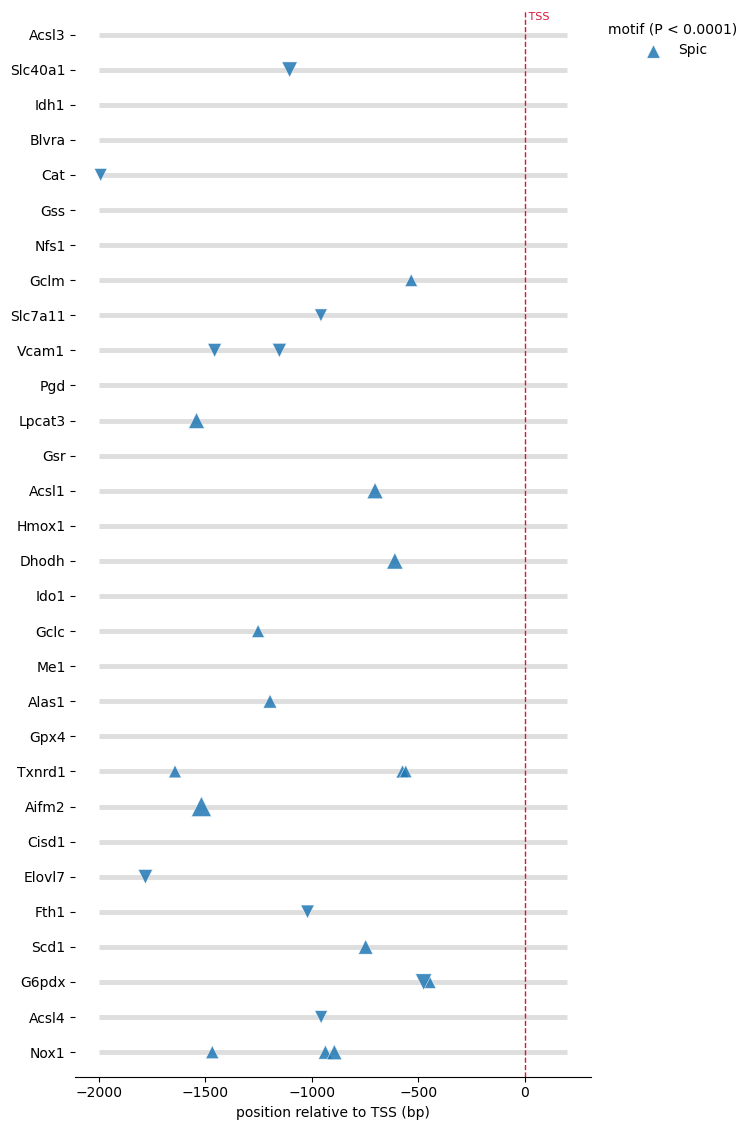

In [14]:


hits_SpiCnet_SpiCmotif = scan(["Spic"], genes=["Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"])             

graph_SpiCnet_SpiCmotif = sitemap(hits_SpiCnet_SpiCmotif)

NameError: name 'hits_SpiCnet_SpiCmotif' is not defined

## Motifs of SpiC, Nfe2l2 and Bach1 possibly regulating the assumed SpiC Network

30 promoters, 4 matrices, 93 sites at P < 0.0001


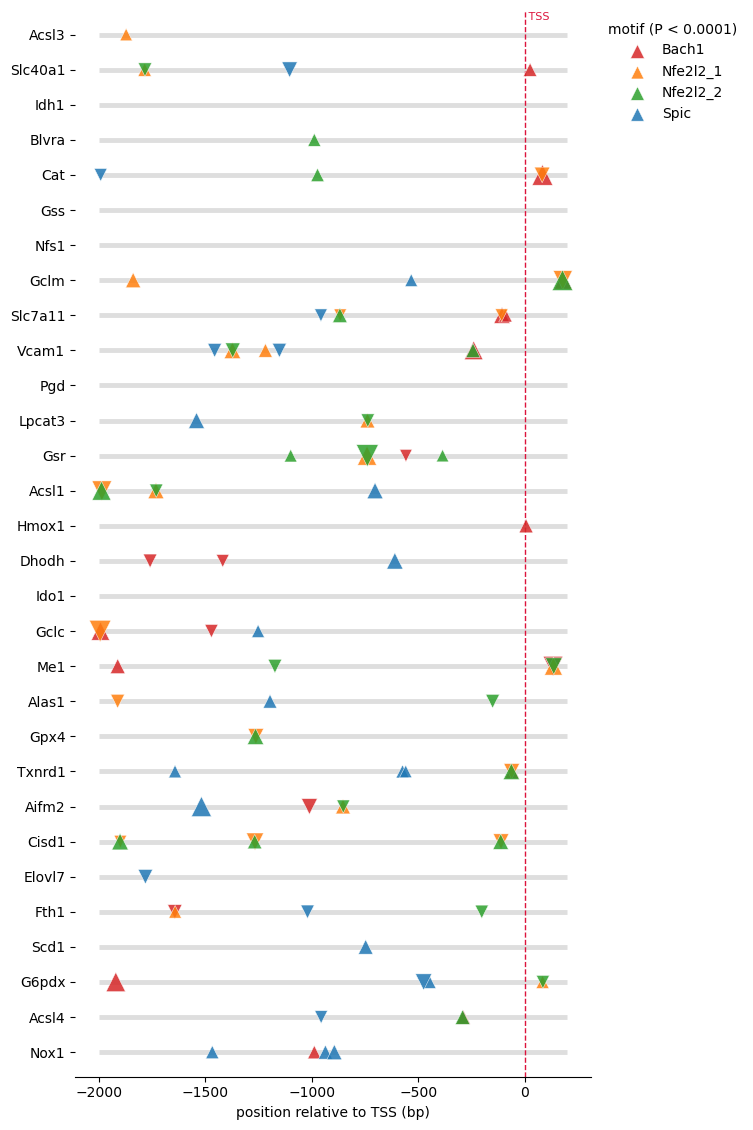

In [15]:


hits_SpiCnet_SpiCNfe2l2Bach1motif = scan(["Spic", "Nfe2l2_1", "Nfe2l2_2", "Bach1"], genes=["Blvra", "Hmox1",  "Vcam1", "Slc40a1", "Gsr", "Slc7a11", "Gclc", "Cat", "Gpx4", "Gclm", "Gss", "Txnrd1",  "Fth1", "Nfs1", "Cisd1", 
         "Aifm2", "Acsl4", "Acsl1", "Lpcat3", "G6pdx", "Pgd", "Me1", "Idh1", "Nox1", "Elovl7", "Ido1", "Alas1", "Dhodh", "Acsl3", "Scd1"])             

graph_SpiCnet_SpiCNfe2l2Bach1motif = sitemap(hits_SpiCnet_SpiCNfe2l2Bach1motif)

## Analysis of Transcription Factors Cross regulation

### SpiC, Nfe2l2, Bach1 Cross Regulation 

5 promoters, 4 matrices, 14 sites at P < 0.0001


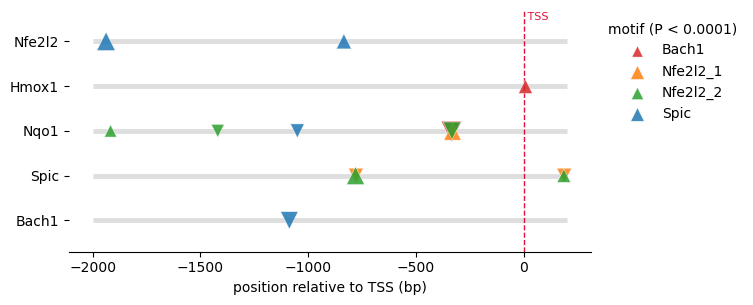

In [16]:


hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif = scan(["Spic", "Nfe2l2_1", "Nfe2l2_2", "Bach1"], genes=["Spic", "Nfe2l2", "Bach1", "Hmox1", "Nqo1"])             

graph_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif = sitemap(hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif)

### Bach1 Regulation of SpiC and Nfe2l2, with control genes

Since Nqo1 promoter wasn't found to have a direct motif, which is strange given that it was confirmed by ChIP-seq to be a direct target. (https://pubmed.ncbi.nlm.nih.gov/15734732/). The issue is that the emsembl definition of canonical favors longer versions of the transcript and the Bach1 is closer to 

3 promoters, 4 matrices, 7 sites at P < 0.0001


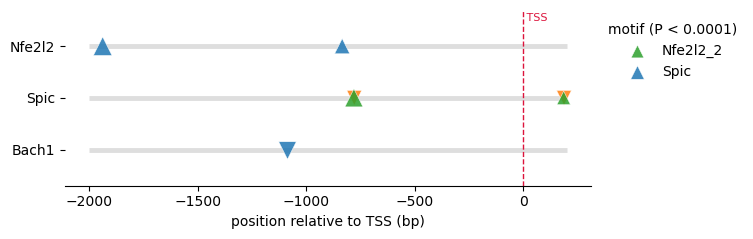

In [17]:


hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif = scan(["Spic", "Nfe2l2_1", "Nfe2l2_2", "Bach1"], genes=["Spic", "Nfe2l2", "Bach1"])             

graph_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif = sitemap(hits_SpiCNfe2l2Bach1prom_SpiCNfe2l2Bach1motif)

## 4.1. Article ready table

For publication, the motif coordinates were matched to the chromosomal regions of the transcript promoters.

### 4.1.1 SpiC regulatory network

In [18]:
#| label: rsat_spic_load
#| code-fold: true
#| code-summary: "Load and Clean RSAT Motif Hits (SpiC Network)"
#| output: false
#open and clean data

Spic_genes = pd.read_csv("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/allpromotors_regulation_matrix_scan.ft.txt", sep="\t", comment=";")           # ';' lines are RSAT metadata
#fts = pd.read_csv("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/FT_cross_regulation_matrix_scan.ft.txt", sep="\t", comment=";")           # ';' lines are RSAT metadata

# prepare data from RSAT tools 
sites = Spic_genes[Spic_genes["ft_type"] == "site"].copy()                 # drop the 'limit' (START_END) rows, not significant

sites[["Gene_Name", "TranscriptID"]] = sites["#seq_id"].str.split("|", expand=True)  # seq_id equals the fasta header given: Gene_Name|TranscriptID
            # origin=end -> TSS sits at -201

sites_filtered =sites[['Gene_Name', 'TranscriptID', 'sequence', 'start', 'end', 'strand', 'Pval', 'sig']].copy()
sites_filtered = sites_filtered.rename(columns={'sequence': 'Motif_Sequence_Found',
                                                'start':   "start_motif_pos_promotor",   # 1-based TSS base
                                                'end': "end_motif_pos_promotor",
                                                'strand': "strand_motif"})

#get info from transcript
meta_transcript = (gtf_sub.df[["Chromosome", "Strand", "transcript_id"]]
                   .rename(columns={"Strand": "Chromosome_Strand",
                                    "transcript_id": "TranscriptID"}))

# one lookup from five_end(); gives the start of the transcript (TSS) in genomic coordinates, 1-based, strand dependent
meta = (gtf_sub.five_end().df
        [["transcript_id", "End"]]
        .rename(columns={"End":    "TSS_chromossomal_localization",   # 1-based TSS base
                         "transcript_id": "TranscriptID"}))

FileNotFoundError: [Errno 2] No such file or directory: '/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/allpromotors_regulation_matrix_scan.ft.txt'

In [ ]:
#| label: rsat_spic_coords
#| code-fold: true
#| code-summary: "Map SpiC Motif Hits to Genomic Coordinates"
#| output: false

meta = meta_transcript.merge(meta, on="TranscriptID", how="left")
sites_filtered = sites_filtered.merge(meta, on="TranscriptID", how="left")

# transcript-relative edges: 0 = TSS base, + = downstream (origin=end anchor at -201)

sites_filtered["start_motif_pos_promotor"] = sites_filtered["start_motif_pos_promotor"].astype(int) + 201
sites_filtered["end_motif_pos_promotor"]   = sites_filtered["end_motif_pos_promotor"].astype(int)   + 201

# nearest edge: end if upstream, start if downstream, 0 if it straddles the TSS
sites_filtered["dist_to_TSS"] = np.where(
    sites_filtered["end_motif_pos_promotor"] < 0, sites_filtered["end_motif_pos_promotor"],
    np.where(sites_filtered["start_motif_pos_promotor"] > 0, sites_filtered["start_motif_pos_promotor"], 0),
)

# to genome (1-based): + adds, - subtracts (edges swap so start <= end)
plus = sites_filtered["Chromosome_Strand"].eq("+")                    # was sites_filtered["Strand"]  -> KeyError
TSS  = sites_filtered["TSS_chromossomal_localization"]                # was sites_filtered["TSS"]     -> KeyError
sites_filtered["motif_genomic_start"] = np.where(plus, TSS + sites_filtered["start_motif_pos_promotor"],
                                                TSS - sites_filtered["end_motif_pos_promotor"]).astype(int)
sites_filtered["motif_genomic_end"]   = np.where(plus, TSS + sites_filtered["end_motif_pos_promotor"],
                                                TSS - sites_filtered["start_motif_pos_promotor"]).astype(int)
sites_filtered["motif_genomic_localization"] = (
    sites_filtered["motif_genomic_start"].astype(str)
    + "-"
    + sites_filtered["motif_genomic_end"].astype(str)
)
sense = sites_filtered["strand_motif"].eq("D")
sites_filtered["motif_genomic_strand"] = np.where(plus == sense, "+", "-")

sites_filtered.drop(columns=["strand_motif", "motif_genomic_end", "motif_genomic_start"], inplace=True)

sites_filtered.to_csv("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/SpiC_allpromoters_motifs_coordinates.csv", index=False)

In [ ]:
#| label: spic_motifs_table
#| code-fold: true
#| code-summary: "SpiC Network Motif Coordinates"
#| output: asis
sites_filtered    # Inspect the SpiC-network motif hits mapped to genomic coordinates


### 4.1.2 Transcription Factors Cross Regulation

In [ ]:
#| label: rsat_ft_load
#| code-fold: true
#| code-summary: "Load and Clean RSAT Motif Hits (TF Cross-Regulation)"
#| output: false
#open and clean data

ft_genes = pd.read_csv("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/ft_cross_regulation_matrix_scan.ft.txt", sep="\t", comment=";")           # ';' lines are RSAT metadata
#fts = pd.read_csv("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/FT_cross_regulation_matrix_scan.ft.txt", sep="\t", comment=";")           # ';' lines are RSAT metadata

# prepare data from RSAT tools 
sites = ft_genes[ft_genes["ft_type"] == "site"].copy()                 # drop the 'limit' (START_END) rows, not significant

sites[["Gene_Name", "TranscriptID"]] = sites["#seq_id"].str.split("|", expand=True)  # seq_id equals the fasta header given: Gene_Name|TranscriptID
            # origin=end -> TSS sits at -201

sites_filtered =sites[['Gene_Name', 'TranscriptID', 'sequence', 'start', 'end', 'strand', 'Pval', 'sig']].copy()
sites_filtered = sites_filtered.rename(columns={'sequence': 'Motif_Sequence_Found',
                                                'start':   "start_motif_pos_promotor",   # 1-based TSS base
                                                'end': "end_motif_pos_promotor",
                                                'strand': "strand_motif"})

#get info from transcript
meta_transcript = (gtf_sub_ft.df[["Chromosome", "Strand", "transcript_id"]]
                   .rename(columns={"Strand": "Chromosome_Strand",
                                    "transcript_id": "TranscriptID"}))

# one lookup from five_end(); gives the start of the transcript (TSS) in genomic coordinates, 1-based, strand dependent
meta = (gtf_sub_ft.five_end().df
        [["transcript_id", "End"]]
        .rename(columns={"End":    "TSS_chromossomal_localization",   # 1-based TSS base
                         "transcript_id": "TranscriptID"}))
print(meta)

In [ ]:
#| label: rsat_ft_coords
#| code-fold: true
#| code-summary: "Map TF Motif Hits to Genomic Coordinates"
#| output: false

meta = meta_transcript.merge(meta, on="TranscriptID", how="left")
sites_filtered = sites_filtered.merge(meta, on="TranscriptID", how="left")

# transcript-relative edges: 0 = TSS base, + = downstream (origin=end anchor at -201)

sites_filtered["start_motif_pos_promotor"] = sites_filtered["start_motif_pos_promotor"].astype(int) + 201
sites_filtered["end_motif_pos_promotor"]   = sites_filtered["end_motif_pos_promotor"].astype(int)   + 201

# nearest edge: end if upstream, start if downstream, 0 if it straddles the TSS
sites_filtered["dist_to_TSS"] = np.where(
    sites_filtered["end_motif_pos_promotor"] < 0, sites_filtered["end_motif_pos_promotor"],
    np.where(sites_filtered["start_motif_pos_promotor"] > 0, sites_filtered["start_motif_pos_promotor"], 0),
)

# to genome (1-based): + adds, - subtracts (edges swap so start <= end)
plus = sites_filtered["Chromosome_Strand"].eq("+")                    # was sites_filtered["Strand"]  -> KeyError
TSS  = sites_filtered["TSS_chromossomal_localization"]                # was sites_filtered["TSS"]     -> KeyError
sites_filtered["motif_genomic_start"] = np.where(plus, TSS + sites_filtered["start_motif_pos_promotor"],
                                                TSS - sites_filtered["end_motif_pos_promotor"]).astype(int)
sites_filtered["motif_genomic_end"]   = np.where(plus, TSS + sites_filtered["end_motif_pos_promotor"],
                                                TSS - sites_filtered["start_motif_pos_promotor"]).astype(int)

sites_filtered["motif_genomic_localization"] = (
    sites_filtered["motif_genomic_start"].astype(str)
    
    + "-"
    + sites_filtered["motif_genomic_end"].astype(str)
)
sense = sites_filtered["strand_motif"].eq("D")
sites_filtered["motif_genomic_strand"] = np.where(plus == sense, "+", "-")

sites_filtered.drop(columns=["strand_motif", "motif_genomic_end", "motif_genomic_start"], inplace=True)


sites_filtered.to_csv("/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Results/FT_cross_regulation_motifs_coordinates.csv", index=False)

In [ ]:
#| label: ft_motifs_table
#| code-fold: true
#| code-summary: "TF Cross-Regulation Motif Coordinates"
#| output: asis
sites_filtered    # Inspect the TF cross-regulation motif hits mapped to genomic coordinates


# 5. Conclusion

This report established a reproducible workflow for extracting promoter sequences and mapping transcription-factor binding motifs in support of the SpiC regulatory analysis, working from the *Mus musculus* GRCm39 reference genome (Ensembl release 116) via `pyranges`.

Promoter regions were defined as −2,000 bp to +200 bp relative to the TSS of each canonical transcript and extracted in a strand-aware manner for two sets of genes: (i) the panel of SpiC-regulated candidate genes and (ii) the *Spic* / *Nfe2l2* pair used to probe direct cross-regulation. The resulting sequences were written to FASTA files, scanned for SpiC and Nfe2l2 motifs with RSAT, and the significant hits were translated from promoter-relative coordinates back to genomic coordinates to build publication-ready tables.

Detection of SpiC and Nfe2l2 motifs within these promoters provides preliminary, sequence-based evidence for potential direct regulatory interactions. Functional validation would be required to distinguish direct regulation from indirect, Nfe2l2-mediated regulation.


# **Session Information**

In [ ]:
#| label: session_information
#| echo: false

## Report package versions and dependencies for reproducibility
print(session_info.show(html=False, dependencies=True))


In [ ]:
#| label: render_html
#| echo: false
#| output: false
#| message: false

##render html
os.system(f'quarto render "/srv/ext_home/ssalazar/projects/GIMM_projects/DNA_018_PromotorSeq_MotifFinder/Notebooks/PromoterExtraction_adapted.ipynb" --to html')
